# Practical No. 03: Autoencoder and Variational Autoencoder for Image Reconstruction

**Name:** Mit Jangid  
**PRN:** 202401110072  
**Batch:** A1  
**Subject:** Generative AI

## Aim
To build a Convolutional Autoencoder and a Variational Autoencoder (VAE) for image reconstruction and generation, and compare their performance using reconstructed images, generated samples and quantitative reconstruction metrics.

## Dataset
MNIST handwritten digits dataset containing 28 × 28 grayscale images of digits 0–9. The official training and test partitions are used. Pixel values are normalized to the range [0, 1].

## Models
1. **Convolutional Autoencoder:** Learns a deterministic compact latent representation and reconstructs the input image.
2. **Convolutional Variational Autoencoder:** Learns a probabilistic latent representation using a mean and log-variance, samples latent vectors using the reparameterization trick, and generates new digit-like images.

The notebook compares reconstruction quality using Mean Squared Error (MSE) and visual inspection. The VAE also reports its reconstruction and KL-divergence losses.

## 1. Import libraries and set reproducibility

In [1]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load and preprocess MNIST

In [2]:
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

# Normalize pixels and add the channel dimension.
x_train = x_train_raw.astype("float32")[..., np.newaxis] / 255.0
x_test = x_test_raw.astype("float32")[..., np.newaxis] / 255.0

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))
print("Training labels:", np.unique(y_train))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28, 1)
Testing images: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0
Training labels: [0 1 2 3 4 5 6 7 8 9]


## 3. Explore the dataset

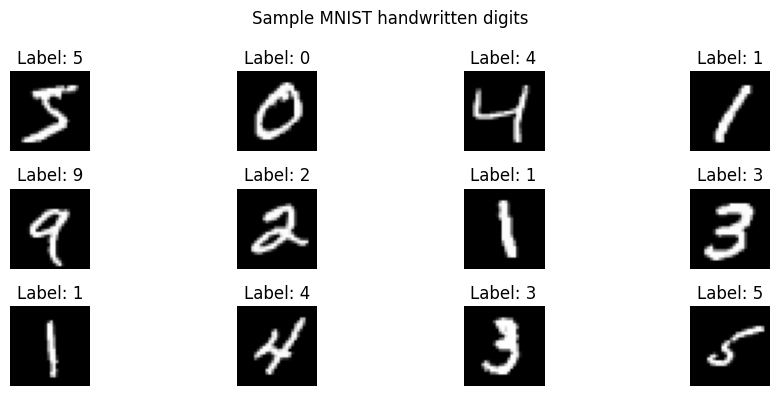

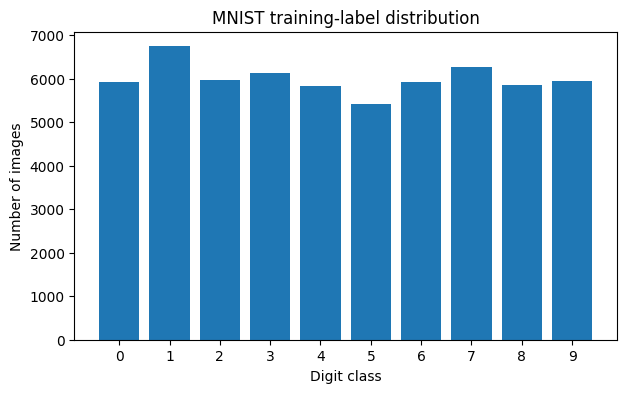

In [3]:
plt.figure(figsize=(10, 4))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST handwritten digits")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(y_train, bins=np.arange(-0.5, 10.5, 1), rwidth=0.8)
plt.xticks(range(10))
plt.xlabel("Digit class")
plt.ylabel("Number of images")
plt.title("MNIST training-label distribution")
plt.show()

## 4. Create training and validation datasets

In [4]:
BATCH_SIZE = 128
train_ds = tf.data.Dataset.from_tensor_slices((x_train, x_train))
train_ds = train_ds.shuffle(10000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((x_test, x_test))
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Training samples:", len(x_train))
print("Validation/test samples:", len(x_test))

Training samples: 60000
Validation/test samples: 10000


## 5. Model 1 – Convolutional Autoencoder

In [5]:
# Encoder: 28x28x1 -> 7x7x64 -> compact latent vector
ae_input = keras.Input(shape=(28, 28, 1), name="ae_input")
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(ae_input)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Flatten()(x)
latent = layers.Dense(32, name="ae_latent")(x)
ae_encoder = keras.Model(ae_input, latent, name="Convolutional_AE_Encoder")

# Decoder: latent vector -> 28x28x1 reconstruction
latent_input = keras.Input(shape=(32,), name="ae_latent_input")
x = layers.Dense(7 * 7 * 64, activation="relu")(latent_input)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
ae_output = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(x)
ae_decoder = keras.Model(latent_input, ae_output, name="Convolutional_AE_Decoder")

ae_reconstruction = ae_decoder(ae_encoder(ae_input))
autoencoder = keras.Model(ae_input, ae_reconstruction, name="Convolutional_Autoencoder")
autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
autoencoder.summary()

Model: "Convolutional_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ae_input (InputLayer)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolutional_AE_Encoder        │ (None, 32)             │       119,200 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolutional_AE_Decoder        │ (None, 28, 28, 1)      │       159,169 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 278,369 (1.06 MB)

 Trainable params: 278,369 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
callbacks_ae = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]
start = time.time()
history_ae = autoencoder.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks_ae,
    verbose=1
)
ae_training_time = time.time() - start
print(f"Autoencoder training time: {ae_training_time/60:.2f} minutes")

Epoch 1/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step - loss: 0.1673 - val_loss: 0.0864
Epoch 2/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0820 - val_loss: 0.0781
Epoch 3/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0772 - val_loss: 0.0756
Epoch 4/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0752 - val_loss: 0.0741
Epoch 5/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0739 - val_loss: 0.0731
Epoch 6/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0731 - val_loss: 0.0725
Epoch 7/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0724 - val_loss: 0.0719
Epoch 8/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0719 - val_loss: 0.0716
Epoch 9/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0714 - val_loss: 0.0713
Epoch 10/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0711 - val_loss: 0.0710
Epoch 11/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0708 - val_loss: 0.0708
Epoch 12/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/st

## 6. Reconstruct images using the Autoencoder

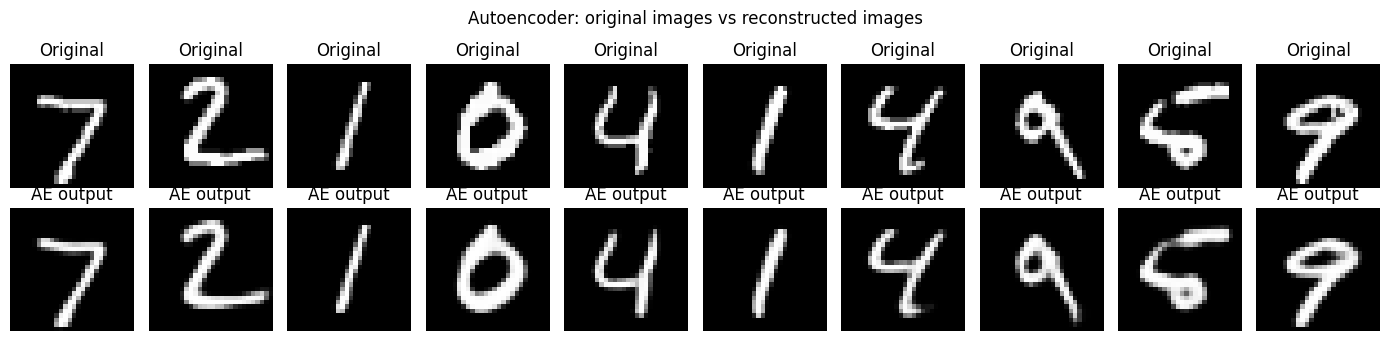

In [7]:
n = 10
originals = x_test[:n]
ae_reconstructed = autoencoder.predict(originals, verbose=0)

plt.figure(figsize=(14, 3.5))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(originals[i].squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2, n, n + i + 1)
    plt.imshow(ae_reconstructed[i].squeeze(), cmap="gray")
    plt.title("AE output")
    plt.axis("off")
plt.suptitle("Autoencoder: original images vs reconstructed images")
plt.tight_layout()
plt.show()

## 7. Model 2 – Convolutional Variational Autoencoder (VAE)

In [8]:
LATENT_DIM = 16

class Sampling(layers.Layer):
    # Reparameterization trick: z = mean + exp(0.5 * log_var) * epsilon
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

vae_input = keras.Input(shape=(28, 28, 1), name="vae_input")
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(vae_input)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)
z = Sampling(name="sampling")([z_mean, z_log_var])
vae_encoder = keras.Model(vae_input, [z_mean, z_log_var, z], name="VAE_Encoder")

decoder_input = keras.Input(shape=(LATENT_DIM,), name="z_sampling")
x = layers.Dense(7 * 7 * 64, activation="relu")(decoder_input)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
decoder_output = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(x)
vae_decoder = keras.Model(decoder_input, decoder_output, name="VAE_Decoder")

class VariationalAutoencoder(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]

    def call(self, inputs, training=False):
        mean, log_var, z_sample = self.encoder(inputs, training=training)
        return self.decoder(z_sample, training=training)

    def _compute_losses(self, data, training):
        mean, log_var, z_sample = self.encoder(data, training=training)
        reconstruction = self.decoder(z_sample, training=training)
        # Sum pixel-wise binary cross-entropy for each image, then average batch.
        pixel_loss = keras.losses.binary_crossentropy(data, reconstruction)
        reconstruction_loss = tf.reduce_mean(tf.reduce_sum(pixel_loss, axis=(1, 2)))
        kl_per_image = -0.5 * tf.reduce_sum(
            1.0 + log_var - tf.square(mean) - tf.exp(log_var), axis=1
        )
        kl_loss = tf.reduce_mean(kl_per_image)
        total_loss = reconstruction_loss + kl_loss
        return total_loss, reconstruction_loss, kl_loss

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            total_loss, reconstruction_loss, kl_loss = self._compute_losses(data, training=True)
        gradients = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        total_loss, reconstruction_loss, kl_loss = self._compute_losses(data, training=False)
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

vae = VariationalAutoencoder(vae_encoder, vae_decoder, name="Convolutional_VAE")
vae.compile(optimizer=keras.optimizers.Adam(1e-3))
print("VAE encoder:")
vae_encoder.summary()
print("VAE decoder:")
vae_decoder.summary()

VAE encoder:


Model: "VAE_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ vae_input           │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 14, 14,    │        320 │ vae_input[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3136)      │          0 │ conv2d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │    401,536 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │      2,064 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │      2,064 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 16)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 424,480 (1.62 MB)

 Trainable params: 424,480 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ z_sampling (InputLayer)         │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3136)           │        53,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,993 (425.75 KB)

 Trainable params: 108,993 (425.75 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
callbacks_vae = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]
start = time.time()
history_vae = vae.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_vae,
    verbose=1
)
vae_training_time = time.time() - start
print(f"VAE training time: {vae_training_time/60:.2f} minutes")

Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - kl_loss: 11.0860 - loss: 183.7655 - reconstruction_loss: 172.6795 - val_kl_loss: 17.9720 - val_loss: 129.7540 - val_reconstruction_loss: 111.7820
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 19.2845 - loss: 119.3367 - reconstruction_loss: 100.0522 - val_kl_loss: 19.7164 - val_loss: 111.7823 - val_reconstruction_loss: 92.0658
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 20.2540 - loss: 110.1718 - reconstruction_loss: 89.9178 - val_kl_loss: 20.3548 - val_loss: 107.3588 - val_reconstruction_loss: 87.0040
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 20.5724 - loss: 107.0564 - reconstruction_loss: 86.4840 - val_kl_loss: 20.9858 - val_loss: 105.8644 - val_reconstruction_loss: 84.8786
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 20.7750 - loss: 105.3078 - reconstruction_loss: 84.5327 - val_kl_loss: 20.7526 - val_loss: 104.1830 - val_reconstruction_loss: 83.4304
Epoch

## 8. Reconstruct images using the VAE

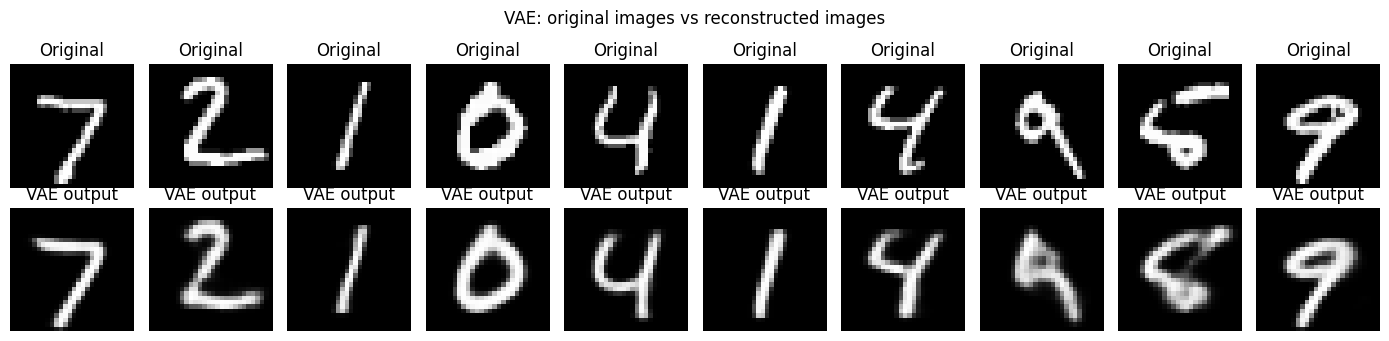

In [10]:
vae_reconstructed = vae.predict(originals, verbose=0)

plt.figure(figsize=(14, 3.5))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(originals[i].squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2, n, n + i + 1)
    plt.imshow(vae_reconstructed[i].squeeze(), cmap="gray")
    plt.title("VAE output")
    plt.axis("off")
plt.suptitle("VAE: original images vs reconstructed images")
plt.tight_layout()
plt.show()

## 9. Generate new images from the latent space

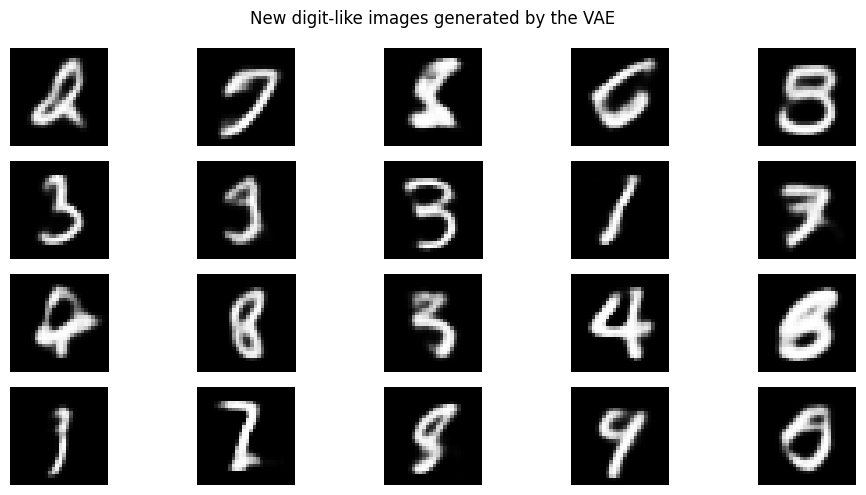

In [11]:
# Sample latent vectors from the standard normal prior and decode them.
num_generated = 20
random_latents = tf.random.normal(shape=(num_generated, LATENT_DIM), seed=SEED)
generated_images = vae_decoder.predict(random_latents, verbose=0)

plt.figure(figsize=(10, 5))
for i in range(num_generated):
    plt.subplot(4, 5, i + 1)
    plt.imshow(generated_images[i].squeeze(), cmap="gray")
    plt.axis("off")
plt.suptitle("New digit-like images generated by the VAE")
plt.tight_layout()
plt.show()

## 10. Compare reconstruction quality using MSE

In [12]:
def mean_squared_error_per_image(original, reconstructed):
    return np.mean(np.square(original - reconstructed), axis=(1, 2, 3))

ae_mse = mean_squared_error_per_image(x_test, autoencoder.predict(x_test, batch_size=256, verbose=0))
vae_mse = mean_squared_error_per_image(x_test, vae.predict(x_test, batch_size=256, verbose=0))

comparison = pd.DataFrame([
    {"Model": "Convolutional Autoencoder", "Mean MSE": float(np.mean(ae_mse)),
     "Median MSE": float(np.median(ae_mse)), "Training time (min)": ae_training_time/60},
    {"Model": "Convolutional VAE", "Mean MSE": float(np.mean(vae_mse)),
     "Median MSE": float(np.median(vae_mse)), "Training time (min)": vae_training_time/60}
])
display(comparison.round(5))

,Model,Mean MSE,Median MSE,Training time (min)
0,Convolutional Autoencoder,0.00345,0.00298,1.06230
1,Convolutional VAE,0.01248,0.01142,1.13796


## 11. Plot training curves

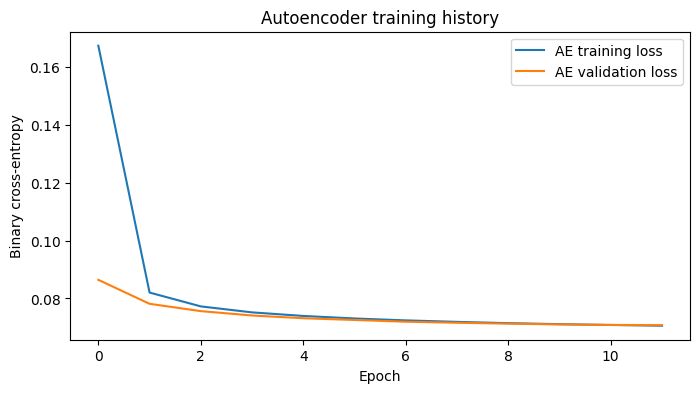

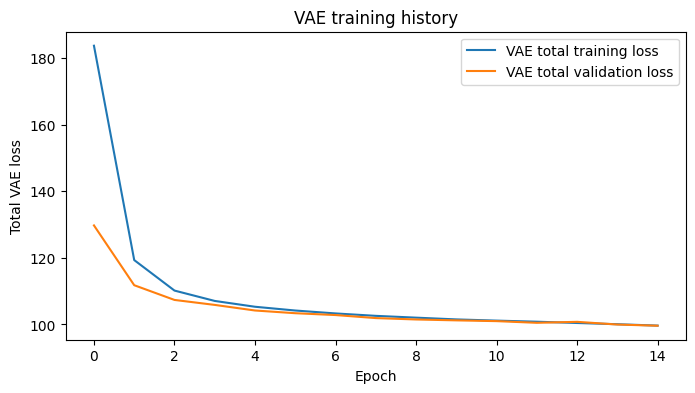

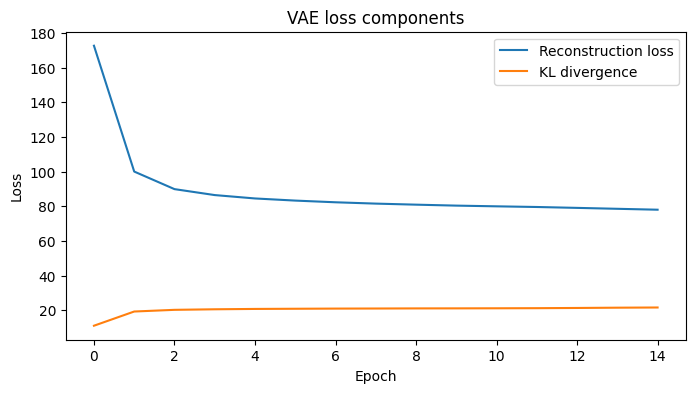

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(history_ae.history["loss"], label="AE training loss")
plt.plot(history_ae.history["val_loss"], label="AE validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Autoencoder training history")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history_vae.history["loss"], label="VAE total training loss")
plt.plot(history_vae.history["val_loss"], label="VAE total validation loss")
plt.xlabel("Epoch")
plt.ylabel("Total VAE loss")
plt.title("VAE training history")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history_vae.history["reconstruction_loss"], label="Reconstruction loss")
plt.plot(history_vae.history["kl_loss"], label="KL divergence")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE loss components")
plt.legend()
plt.show()

## 12. Visualize the learned latent space

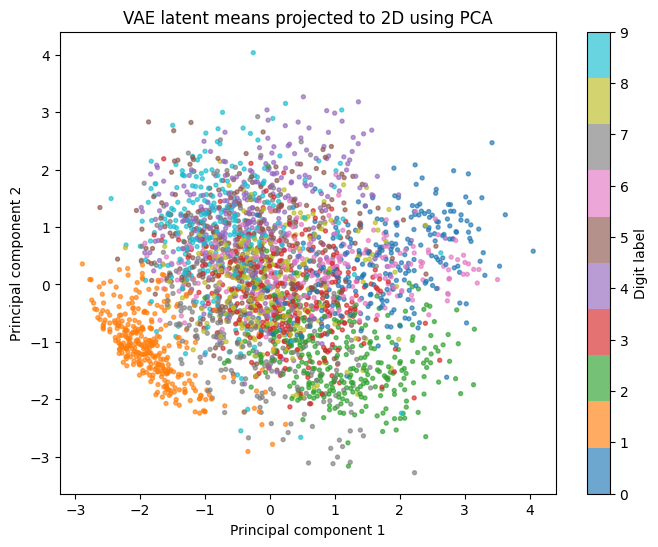

In [14]:
# Display the 2D projection of the VAE mean vectors using PCA.
from sklearn.decomposition import PCA

z_means, z_log_vars, _ = vae_encoder.predict(x_test[:3000], batch_size=256, verbose=0)
z_2d = PCA(n_components=2, random_state=SEED).fit_transform(z_means)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(z_2d[:, 0], z_2d[:, 1], c=y_test[:3000],
                      cmap="tab10", s=8, alpha=0.65)
plt.colorbar(scatter, ticks=range(10), label="Digit label")
plt.title("VAE latent means projected to 2D using PCA")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.show()

## 13. Save models and results

In [15]:
comparison.to_csv("mnist_autoencoder_vae_comparison.csv", index=False)
autoencoder.save("mit_jangid_mnist_autoencoder.keras")
vae_encoder.save("mit_jangid_mnist_vae_encoder.keras")
vae_decoder.save("mit_jangid_mnist_vae_decoder.keras")
print("Saved AE, VAE encoder, VAE decoder and comparison CSV.")

Saved AE, VAE encoder, VAE decoder and comparison CSV.


## Result
A Convolutional Autoencoder and a Convolutional Variational Autoencoder were trained on MNIST. The notebook generates side-by-side reconstruction plots, new images sampled from the VAE latent prior, training curves, latent-space visualization and a test-set MSE comparison. The actual numerical results are produced by executing the notebook.

## Conclusion
The Convolutional Autoencoder learns a deterministic latent code that is useful for reconstructing input digits. The Variational Autoencoder learns a distribution over latent representations through its mean and log-variance vectors and uses the reparameterization trick to sample latent codes. This probabilistic structure allows the VAE to generate new digit-like images by sampling from a standard normal latent prior. Their reconstruction performance is compared using MSE and visual inspection, while the VAE's reconstruction and KL-divergence losses describe its training objective.

## References
1. MNIST database of handwritten digits: http://yann.lecun.com/exdb/mnist/
2. Kingma, D. P. and Welling, M. (2014). Auto-Encoding Variational Bayes.
3. TensorFlow/Keras documentation: https://www.tensorflow.org/